# How to use viewmastR

viewmastR predicts the cell types of a query dataset from a labelled reference. This
tutorial selects shared variable genes, trains a model, and checks its predictions. It makes
the figure in the README. It follows the R article
[How to use viewmastR](https://furlan-lab.github.io/viewmastR/articles/HowTo.html).

| Role | Dataset |
|---|---|
| Reference | BoneMarrowMap healthy bone marrow atlas (Zeng et al. 2025), finest labels `CellType` (55 types), balanced to 3,000 cells per type with `augment_data()` (tutorial 04) |
| Query | T-cell-depleted bone marrow, multiome RNA, 8,627 cells with the authors' 18 labels and UMAP (Persad et al. 2023; the file the [Mellon](https://github.com/settylab/Mellon) tutorial uses) |

## Install

```bash
uv pip install "git+https://github.com/jacob-greene/py-viewmastR"
```

A Rust toolchain (1.86 or newer) builds the burn backend during the install.

## Load the data

Copy `data_paths.example.json` to `data_paths.json` and set `cache_dir`. The data
download on first use (BoneMarrowMap 3.7 GB, query 2.5 GB). The query is used as published:
raw counts, the authors' labels and their UMAP. Nothing is re-normalised or re-embedded.

`bonemarrowmap_augmented()` builds the reference once and caches it (about 12 GB of
memory). Of each type it holds out 20 % of the real cells (at most 1,000). It then
balances the other cells to 3,000 per type: large types are down-sampled, and rare types
get simulated cells. The held-out cells are real and never simulated, so they give an
honest accuracy below.

In [1]:
import matplotlib.pyplot as plt
import scanpy as sc
import viewmastr as vm
import readme_panels as rp
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
plt.rcParams.update(rp.STYLE)
label = "CellType"
ref, held = td.bonemarrowmap_augmented(label, norm_number=3000)
query = td.bm_tcelldep()
print("reference", ref.shape, "of which simulated", int(ref.obs["simulated"].sum()))
print("held out", held.shape, "query", query.shape)

reference (165000, 34009) of which simulated 46491
held out (35575, 34009) query (8627, 17226)


## The reference cell types

These are the labels viewmastR learns. The plot shows the real BoneMarrowMap cells on the
atlas's stored UMAP. Simulated cells have no position on it.

The plots in this tutorial are the panels of the README figure, drawn with the same code.
`readme_panels` (next to this notebook) holds that code. `celltype_colors` colours the 55
reference types and the authors' labels; like types share a hue with the matching author label.

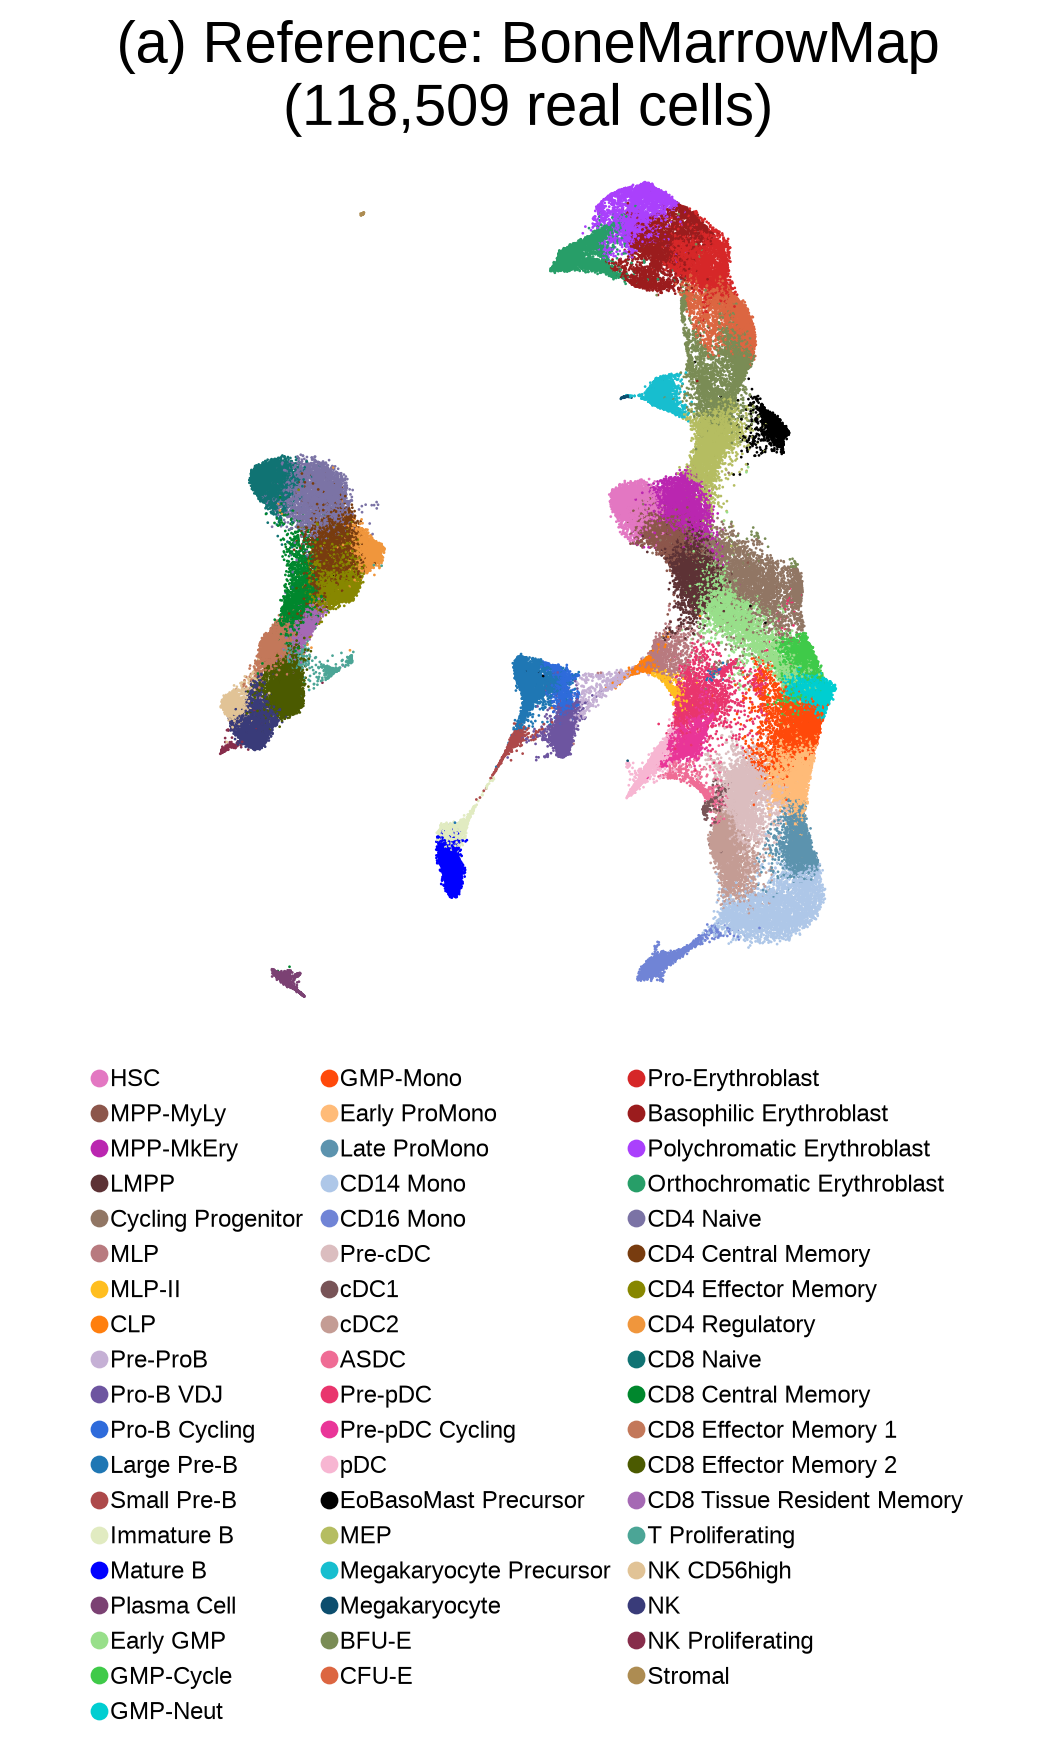

In [2]:
real = ref[~ref.obs["simulated"].to_numpy()].copy()
rp.umap_figure(real.obsm["X_umap"], real.obs[label],
               f"(a) Reference: BoneMarrowMap\n({real.n_obs:,} real cells)")
plt.show()

## The query's own labels

The authors' labels use different names from the reference, but they show which
populations to expect. The UMAP is the one stored in the file; viewmastR does not use it.

celltype
Mono          4665
NaiveB         976
MonoPre        645
EryPre2        326
EryPre1        315
cDC            296
preB           217
MyeloidPre     186
Ery            157
proB           155
pDC            131
MylEry         122
HMP            121
MEP             99
HSC             95
preproB         59
CLP             38
Mega            24


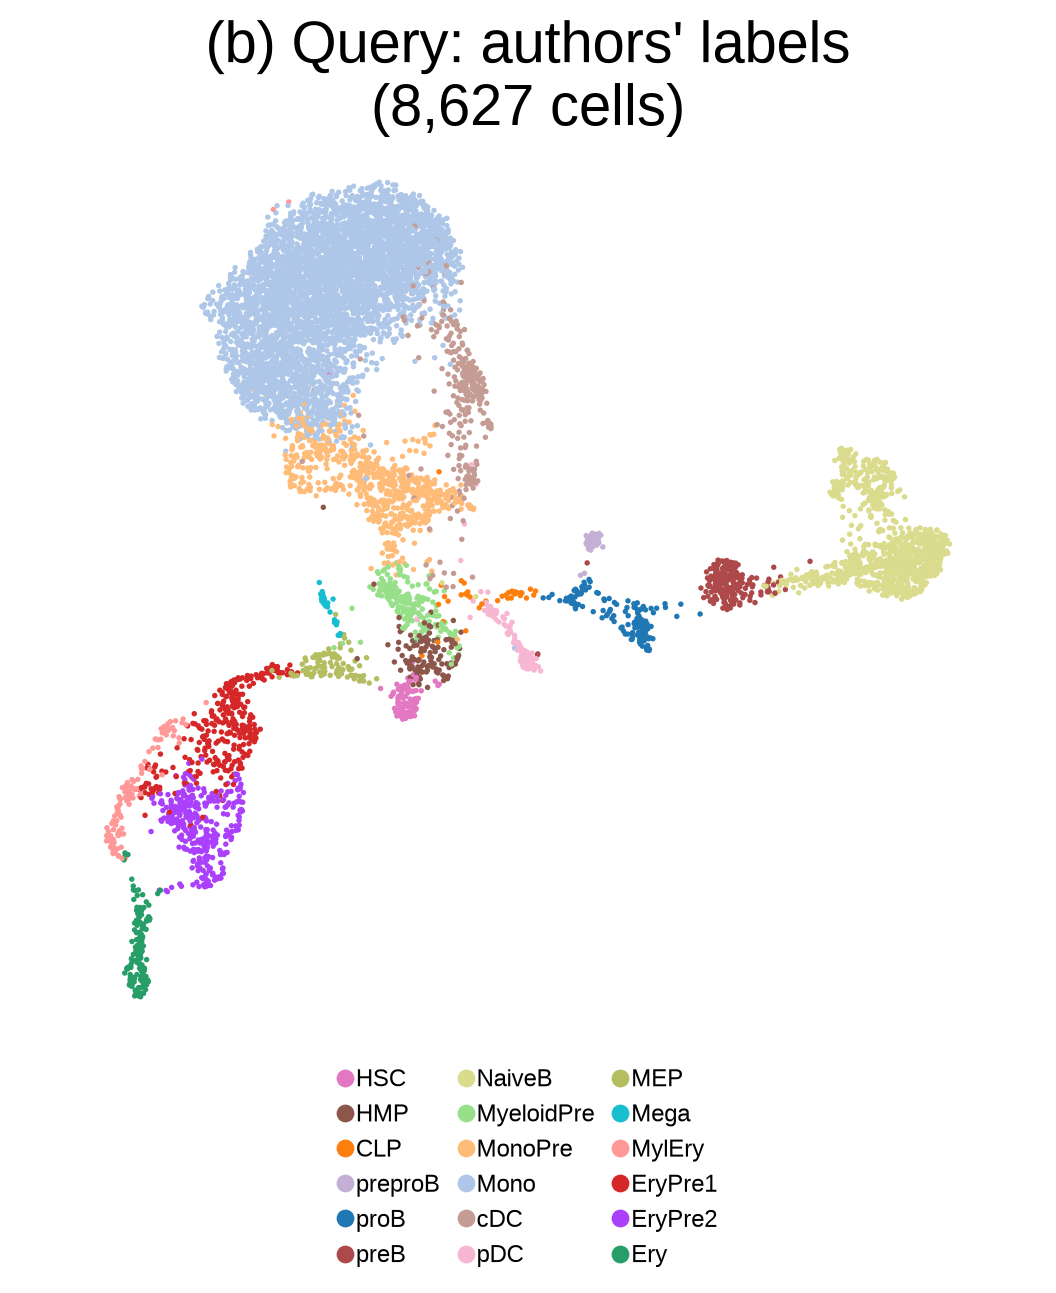

In [3]:
print(query.obs["celltype"].value_counts().to_string())
rp.umap_figure(query.obsm["X_umap"], query.obs["celltype"],
               f"(b) Query: authors' labels\n({query.n_obs:,} cells)", size=rp.QSIZE)
plt.show()

## Find shared variable genes

viewmastR works best on genes that vary in both datasets. For each dataset, compute the
per-gene dispersion, keep the 10,000 most dispersed genes in a mean-expression window, and
intersect the two lists. Selected genes are red; the line is the fitted mean-dispersion trend.

3878 shared variable genes


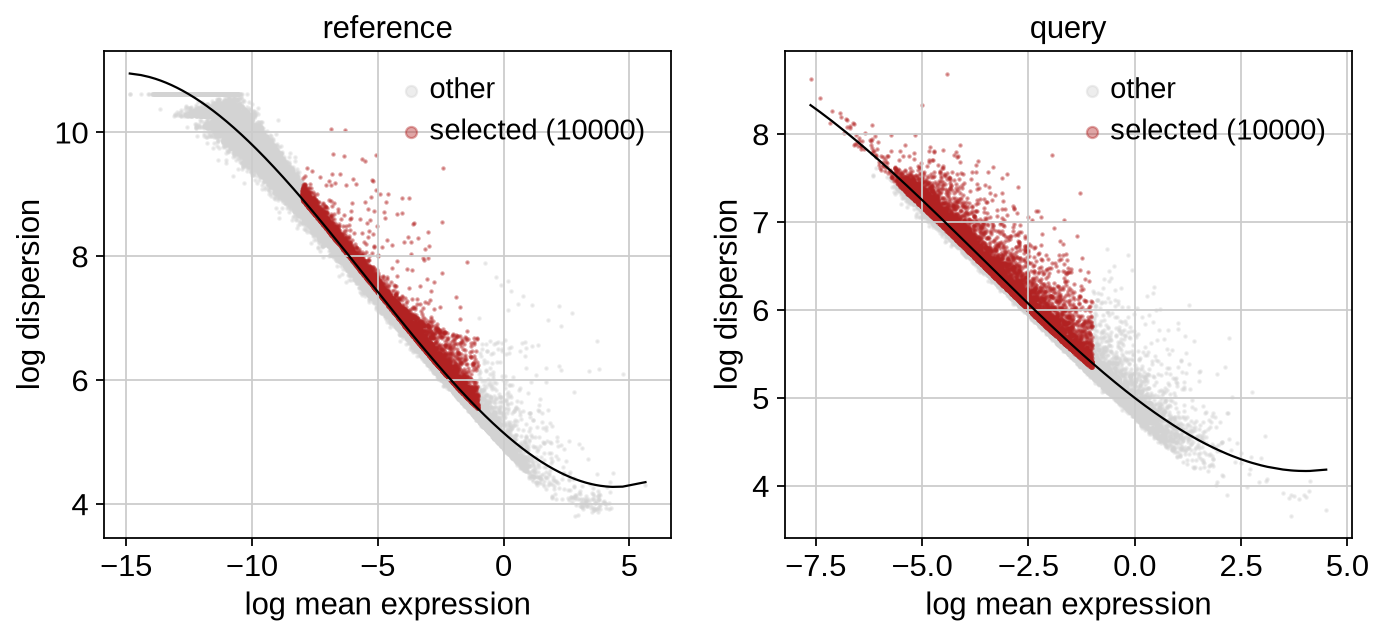

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, a) in zip(axes, [("reference", ref), ("query", query)]):
    vm.calculate_feature_dispersion(a)
    vm.select_features(a, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
    vm.plot_feature_dispersion(a, ax=ax).set_title(name)
vgr = set(vm.get_selected_features(ref))
vg = [g for g in vm.get_selected_features(query) if g in vgr]
print(f"{len(vg)} shared variable genes")

## Run viewmastR

`viewmastR()` trains on the reference and writes the prediction to
`query.obs["viewmastR_pred"]`. `return_probs=True` also adds class probabilities, and
`return_type="list"` returns the training history and the saved model with the labelled
query. `seed` with `workers=1` makes training reproducible.

The legend lists the types called on at least 10 query cells. It lists a mature type only if
the authors label that population too. The heatmap below keeps all 55 types.

viewmastR: 3878 features, 55 classes, 132000 train / 33000 test cells


[epoch 1 | train accuracy 73.955% | validation accuracy 80.012%]


[epoch 2 | train accuracy 82.417% | validation accuracy 80.703%]


[epoch 3 | train accuracy 84.208% | validation accuracy 80.894%]


[epoch 4 | train accuracy 85.484% | validation accuracy 80.976%]


[epoch 5 | train accuracy 86.602% | validation accuracy 81.030%]


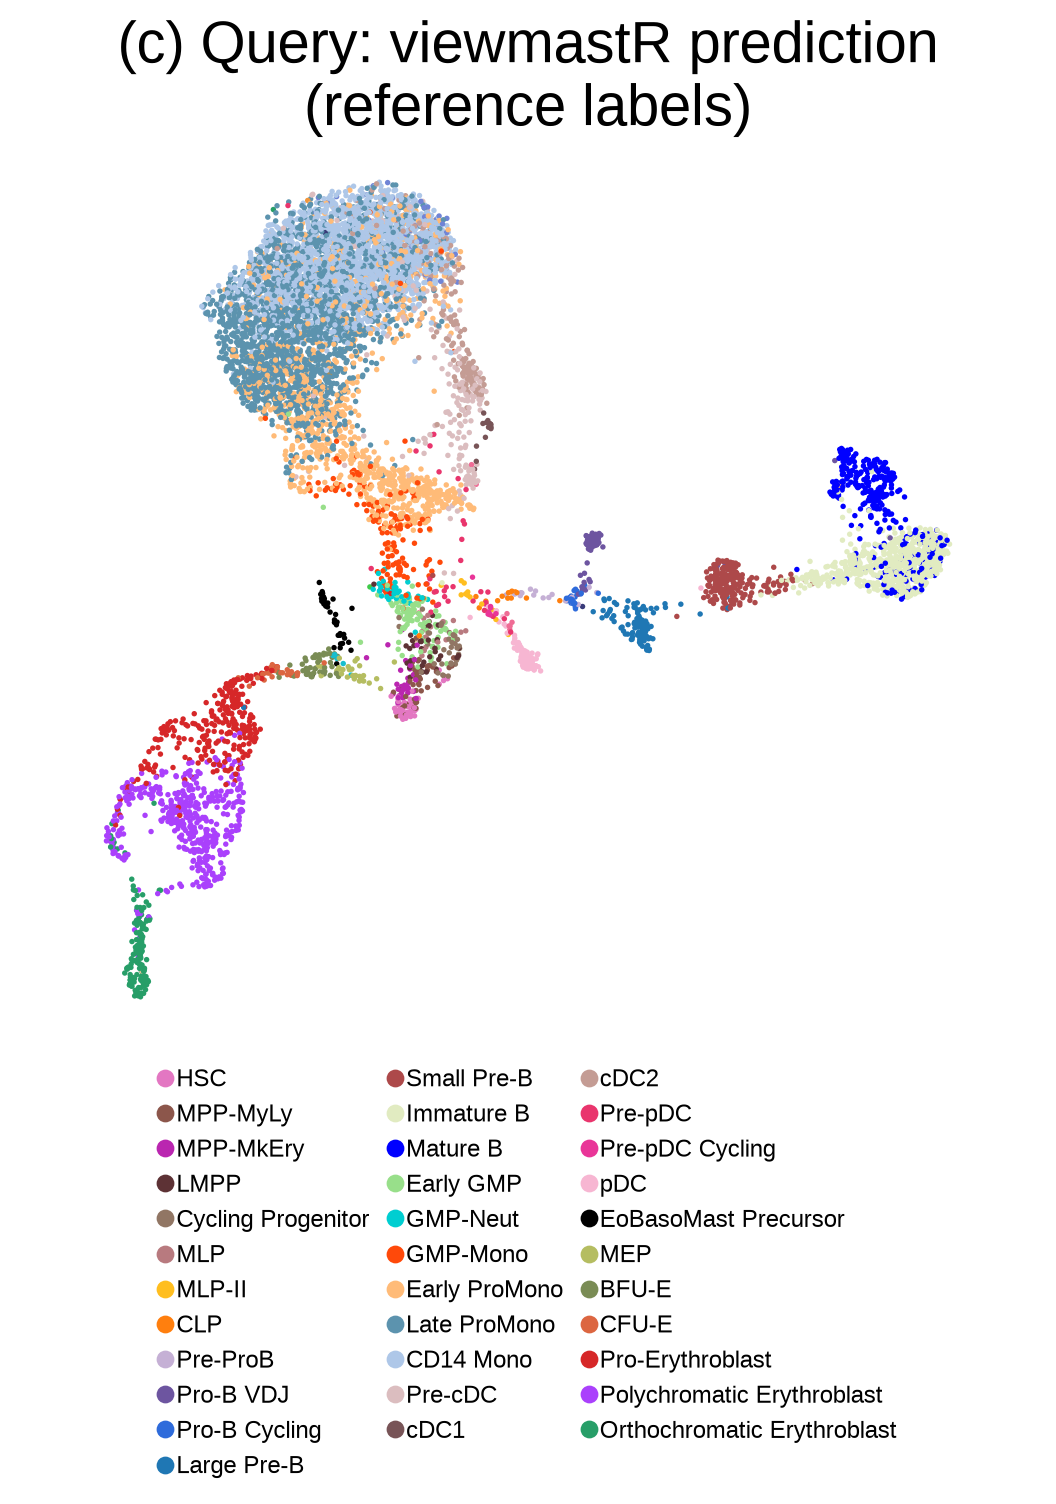

In [5]:
res = vm.viewmastR(query, ref, label, selected_features=vg, seed=20261103, workers=1,
                   return_type="list", return_probs=True)
query = res.adata
shown, _ = rp.prediction_legend(query.obs["viewmastR_pred"], query.obs["celltype"])
rp.umap_figure(query.obsm["X_umap"], query.obs["viewmastR_pred"],
               "(c) Query: viewmastR prediction\n(reference labels)", legend=shown, size=rp.QSIZE)
plt.show()

## Compare with the author labels

Columns are the author labels; rows are the predictions; colour is the fraction of each
column. The two vocabularies differ, so read this as a mapping, not an accuracy.
Rows with no cells are types that viewmastR did not call.
The atlas types are finer, so several author labels split into stages:

| Author label | Main predicted types |
|---|---|
| `Mono` | `CD14 Mono`, `Late ProMono`, `Early ProMono` |
| `NaiveB` | `Immature B`, `Mature B` |
| `HSC` | `HSC`, `MPP-MkEry`, `MPP-MyLy` |
| `EryPre1` | `Pro-Erythroblast`, `Polychromatic Erythroblast` |

All 24 author `Mega` cells get `EoBasoMast Precursor`, not a megakaryocyte type.

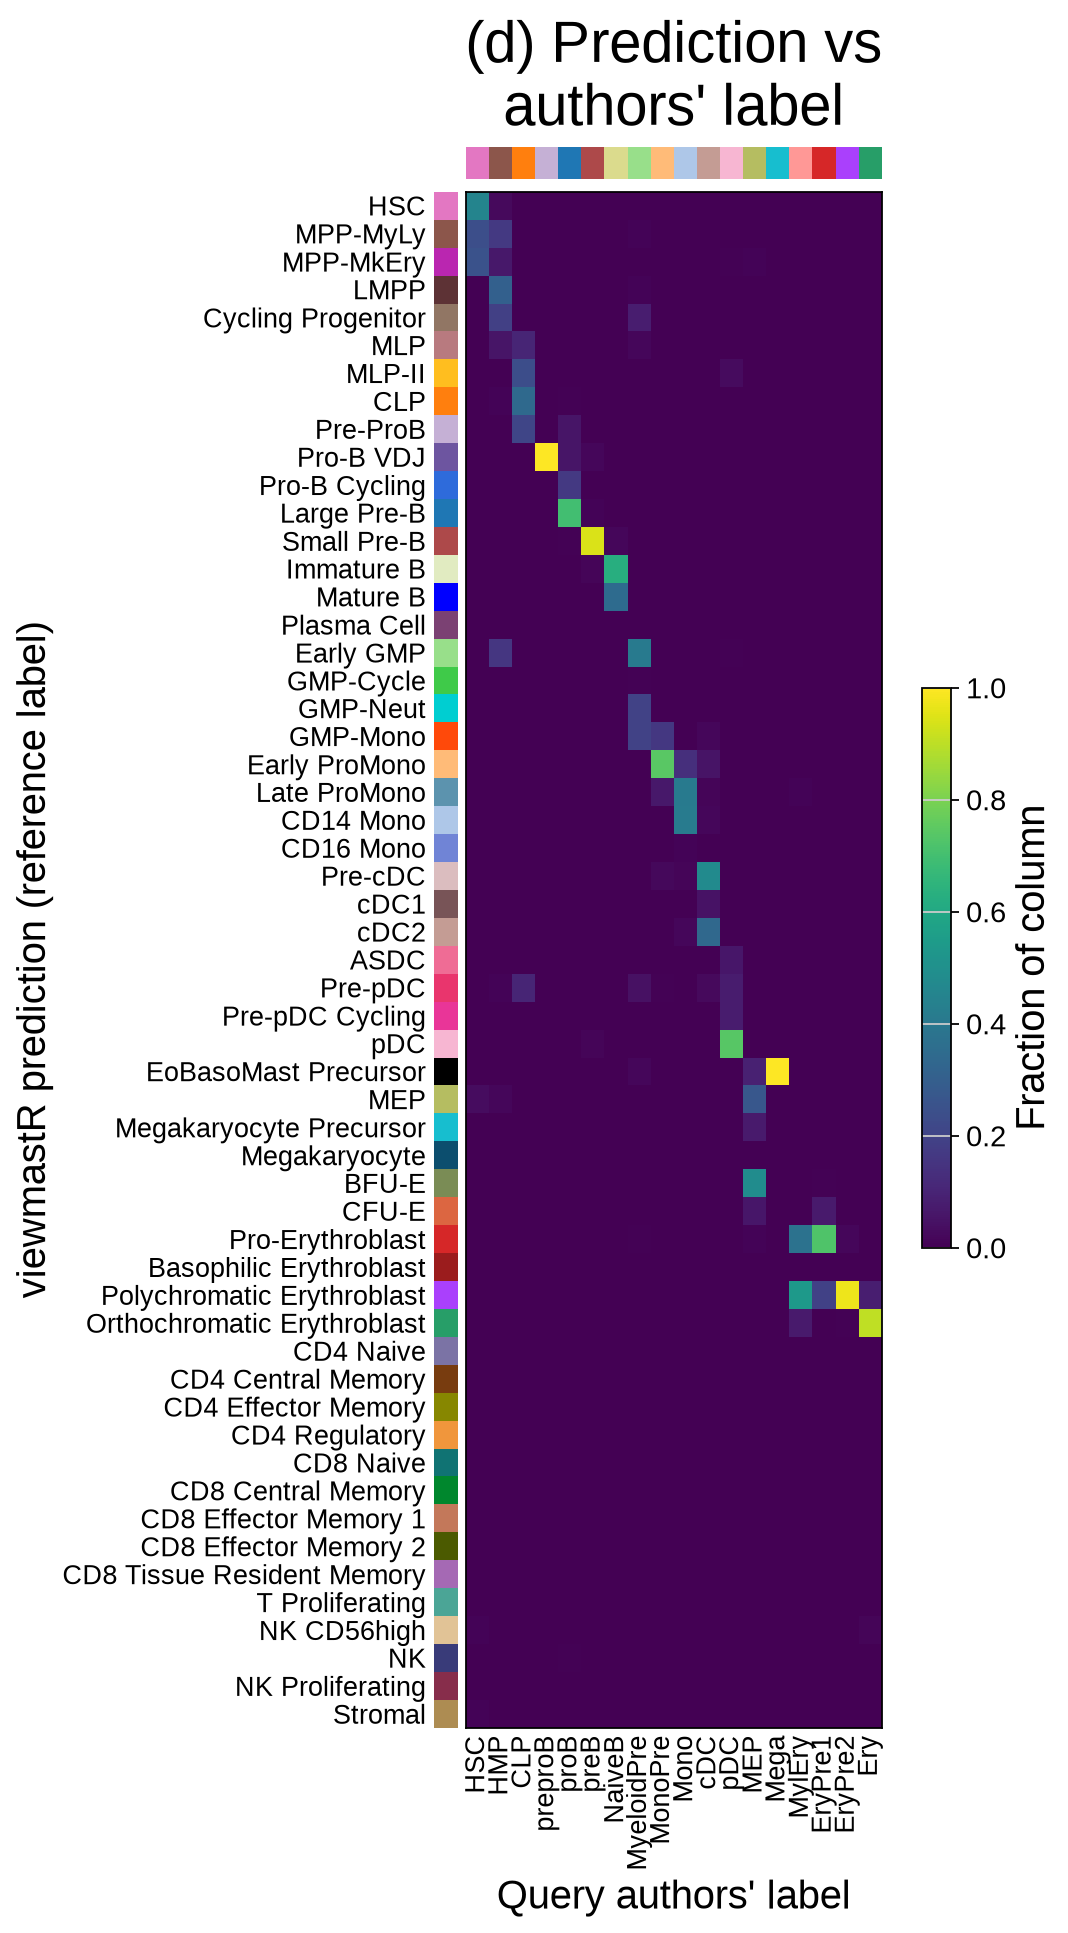

In [6]:
counts, frac = rp.label_fraction(query.obs["viewmastR_pred"], query.obs["celltype"])
fig = plt.figure(figsize=(6.5, 11.5))
rp.heatmap_panel(fig, frac, 3.0, 5.6, 1.5, 11.1, cbar=(5.85, 4.5, 0.18, 3.5))
plt.show()

`vm.confusion_matrix(pred, author)` draws a quick version of this plot with the cell counts.

## Training history

The list result holds the per-epoch accuracy and loss. If training loss keeps falling
while validation loss rises, the model over-fits. The validation cells here come from the
augmented reference, so some are simulated.

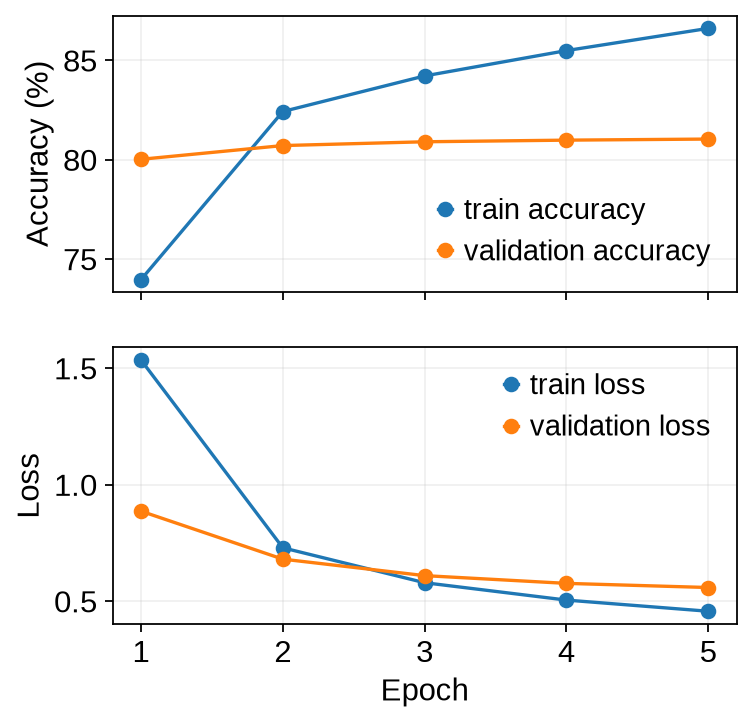

In [7]:
vm.plot_training_data(res)
plt.show()

## Accuracy on held-out real cells

`viewmastR_infer()` labels the held-out real reference cells with the saved model.
Recall = share of a type's held-out cells that get the right label.

In [8]:
vm.viewmastR_infer(held, res.model_dir, query_celldata_col="pred")
hit = held.obs["pred"].astype(str) == held.obs[label].astype(str)
print(f"accuracy {hit.mean():.3f}, mean recall over types {hit.groupby(held.obs[label], observed=True).mean().mean():.3f}")
print(hit.groupby(held.obs[label], observed=True).mean().round(3).sort_values().to_string())

accuracy 0.729, mean recall over types 0.737
CellType
MPP-MyLy                       0.476
CD8 Central Memory             0.481
CLP                            0.496
MLP                            0.512
NK Proliferating               0.535
LMPP                           0.554
T Proliferating                0.569
CD4 Central Memory             0.573
GMP-Mono                       0.581
GMP-Cycle                      0.585
Early ProMono                  0.587
Pro-Erythroblast               0.593
MPP-MkEry                      0.604
CD4 Naive                      0.625
Basophilic Erythroblast        0.643
Early GMP                      0.645
CFU-E                          0.669
CD4 Effector Memory            0.678
Pre-ProB                       0.688
BFU-E                          0.692
MLP-II                         0.693
Cycling Progenitor             0.699
CD8 Tissue Resident Memory     0.725
Pre-pDC                        0.731
Pre-cDC                        0.732
CD8 Effector Memory 2

## Probabilities

`return_probs=True` added one `prob_<label>` column per class: the softmax of the model's
log-odds. Four of the 55 classes are shown.

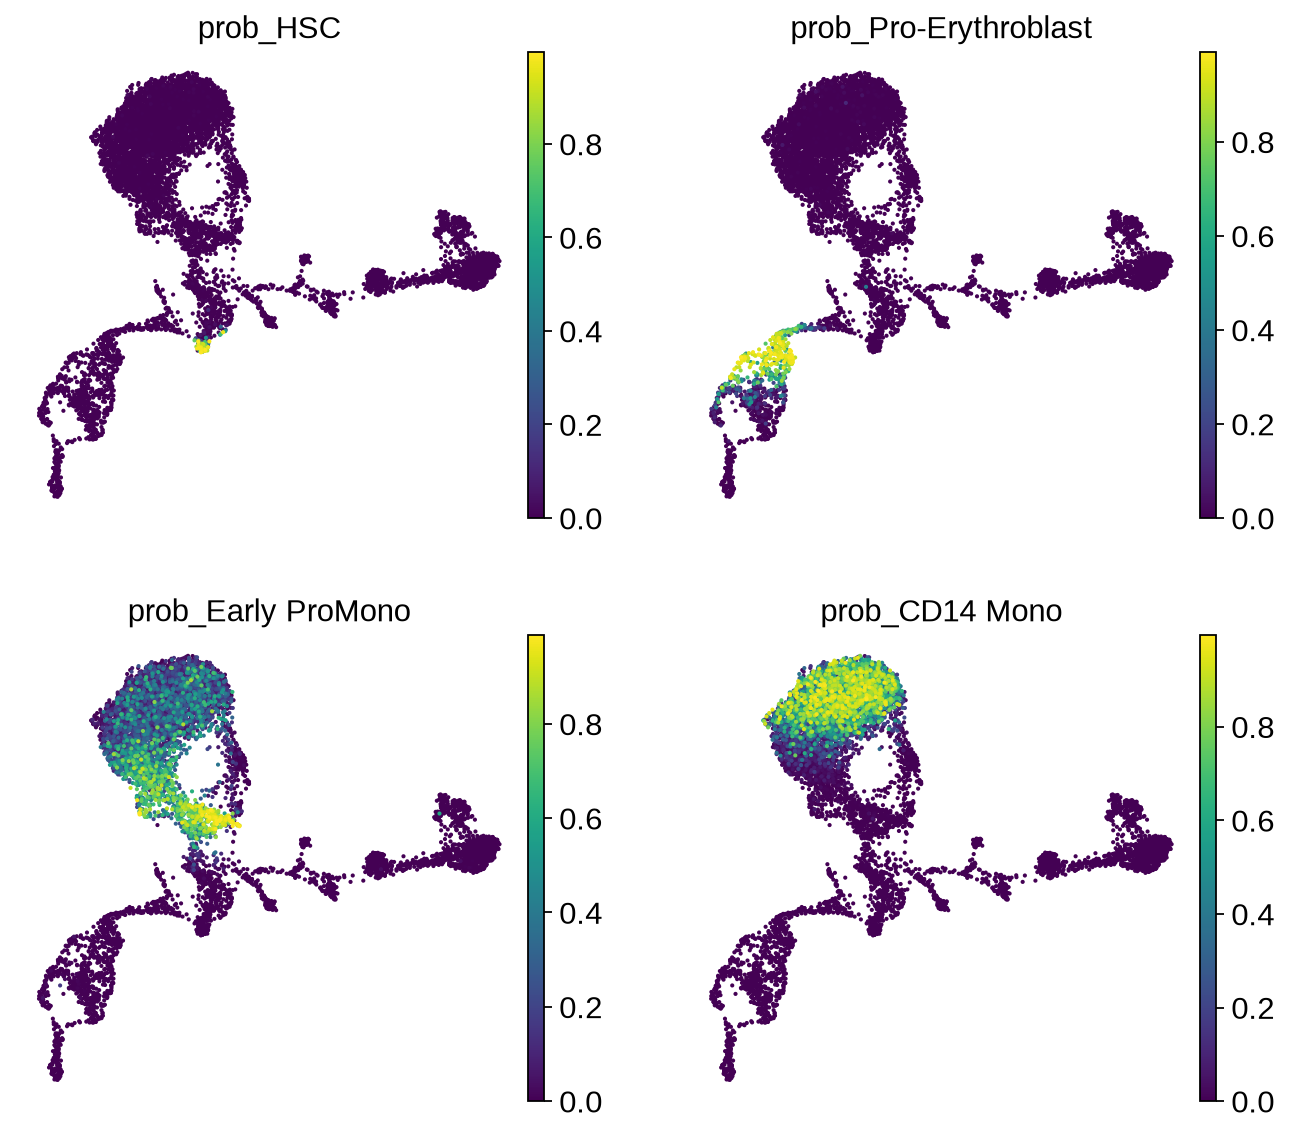

In [9]:
prob_cols = [f"prob_{k}" for k in ("HSC", "Pro-Erythroblast", "Early ProMono", "CD14 Mono")]
sc.pl.umap(query, color=prob_cols, ncols=2, cmap="viridis")

## Versions

In [10]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
